Import Packages and Useful Function

In [1]:
import pandas as pd
from labtools.adtools import sort
import seaborn as sns
import matplotlib.pyplot as plt
# Function for writing dictionary to csv file (used for loss tables)
import csv
def write_dict_to_csv(file_path, dictionary):
    with open(file_path, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(dictionary.keys())
        writer.writerow(dictionary.values())
dir = '/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/SynADs/2024-04-00_w.labtoolsDev/2025-10-14_Reprocess/'
name = 'SynAD_GFP'

Initialize the sort

In [2]:
my_sort = sort.Sort(["/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G1_S9.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G2_S10.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G3_S11.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G4_S12.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G5_S13.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G6_S14.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G7_S15.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/G8_S16.fastq.gz.assembled.fastq"], 
                    bin_counts = [1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000], 
                    bin_values = [492,1328,2316,3444,4916,6832,9952,16581], 
                    design_file = "/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/DesignFiles/PlantSynADs_Design.csv")

Process

In [3]:
activities, total_reads, reads_per_bin, loss_table = my_sort.process(thresh=39, ad_preceder = "GCTAGC", bc_preceder = "GGGCCCG", 
            bc_anteceder = "GGCGCGCC", ad_length = 120, bclength = 14, barcoded = True)

Opening file G1_S9.fastq.gz.assembled.fastq ...
Total parsed reads = 9,571,189                      
Opening file G2_S10.fastq.gz.assembled.fastq ...
Total parsed reads = 10,551,104                      
Opening file G3_S11.fastq.gz.assembled.fastq ...
Total parsed reads = 10,596,847                      
Opening file G4_S12.fastq.gz.assembled.fastq ...
Total parsed reads = 8,208,865                      
Opening file G5_S13.fastq.gz.assembled.fastq ...
Total parsed reads = 11,404,380                      
Opening file G6_S14.fastq.gz.assembled.fastq ...
Total parsed reads = 9,905,593                      
Opening file G7_S15.fastq.gz.assembled.fastq ...
Total parsed reads = 9,061,741                      
Opening file G8_S16.fastq.gz.assembled.fastq ...
Total parsed reads = 12,415,439                      


Outputs

In [4]:
loss_table

{'ad_preceder': 338094,
 'design_file': 5064565.0,
 'thresh': 590635.0,
 'bc_is_na': 8905.0,
 'bc_flanks': 284833,
 'bc_length': 70286}

In [5]:
# Convert Series of tuples to DataFrame with two columns
total_reads_df = total_reads.apply(pd.Series)
# Reset index to convert the tuple index into columns
total_reads_df = total_reads.reset_index()
# Rename the columns
total_reads_df.columns = ['AD', 'BC', 'Reads']
# Count the occurrences of each 'BC' and create a new Series
bc_counts = total_reads_df['BC'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['ADs_per_BC'] = total_reads_df['BC'].map(bc_counts)
# Similarly, count the occurrences of each 'AD' and create a new Series
ad_counts = total_reads_df['AD'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['BCs_per_AD'] = total_reads_df['AD'].map(ad_counts)
# Sum all the reads that have the same sequence in the 'AD' column
total_reads_df['numreads_per_AD'] = total_reads_df.groupby('AD')['Reads'].transform('sum')

activities.reset_index(inplace=True)
# Rename the columns for clarity
activities.rename(columns={'level_0': 'DNAseq', 'level_1': 'BC'}, inplace=True)
activities

,DNAseq,BC,0,1,2,3,4,5,6,7,Activity
0,TCTAGATGGTGGTCTTTGGATAAATTGTCTATTAATTTGTTTTTGA...,GCACAAAAGTGACA,0.377532,0.433241,0.189226,0.000000,0.000000,0.000000,0.000000,0.000000,1199.338586
1,CCACCATTGGATCCATTGTTTTTGGATGAAGATGTTCCATTGTTTT...,ACATAATAATATAA,0.061186,0.220136,0.266271,0.180581,0.157878,0.070476,0.043347,0.000125,3252.130603
2,TTGAAATGTGGTGTTGAATCTTTTTTTTCTTCTTGGGAAAAATCTT...,TGTGTACGAGAGTC,0.515963,0.369596,0.090211,0.022014,0.002126,0.000091,0.000000,0.000000,1040.490551
3,TTGTCTTATTTTTTTGATCATTTGATTGATAATTTGGCTCAATTGT...,TCAAAGGCGTGAAG,0.830856,0.169144,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,633.404585
4,TCTTTGACTGGTCCATTGTCTATTTTGGATTTGGAAGTTGCTTTTT...,ATGACACATGTCTC,0.940229,0.059771,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,541.968904
...,...,...,...,...,...,...,...,...,...,...,...
46643,ATGGCTTCTTTTAATGAAATTTCTGATATTGAAGCTGGTTTGGTTT...,ATCAAACACTTATT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,16581.000000
46644,TTGTTGGATATTGGTTCTGTTCCACCACCATTGGATCCATTGTTTT...,CGCATCATAGATTG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,16581.000000
46645,TTGGAACAAAAAGAAGTTTCTTTGTTGTCTTTTCCACATTCTTTTG...,ATCCTACCCACCAC,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,16581.000000
46646,GAATTGTCTATTTTGGATTTGTTTGATATTCCAAATCCAATTTTGG...,AAAATAAACGTTCG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,16581.000000


QC Analyses

In [6]:
print(total_reads_df.shape, activities.shape)

(46648, 6) (46648, 11)


In [7]:
activities.head(10)

,DNAseq,BC,0,1,2,3,4,5,6,7,Activity
0,TCTAGATGGTGGTCTTTGGATAAATTGTCTATTAATTTGTTTTTGA...,GCACAAAAGTGACA,0.377532,0.433241,0.189226,0.000000,0.000000,0.000000,0.000000,0.000000,1199.338586
1,CCACCATTGGATCCATTGTTTTTGGATGAAGATGTTCCATTGTTTT...,ACATAATAATATAA,0.061186,0.220136,0.266271,0.180581,0.157878,0.070476,0.043347,0.000125,3252.130603
2,TTGAAATGTGGTGTTGAATCTTTTTTTTCTTCTTGGGAAAAATCTT...,TGTGTACGAGAGTC,0.515963,0.369596,0.090211,0.022014,0.002126,0.000091,0.000000,0.000000,1040.490551
3,TTGTCTTATTTTTTTGATCATTTGATTGATAATTTGGCTCAATTGT...,TCAAAGGCGTGAAG,0.830856,0.169144,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,633.404585
4,TCTTTGACTGGTCCATTGTCTATTTTGGATTTGGAAGTTGCTTTTT...,ATGACACATGTCTC,0.940229,0.059771,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,541.968904
5,TTGTCTGATGAATTTGAACAATTGGATTTGGCTACTAATCAAGTTG...,GAGAAACGTCACTC,0.639433,0.300624,0.057453,0.002375,0.000114,0.000000,0.000000,0.000000,855.632047
6,GAAGCTGCTGAATTGTTGGAACCAATTGATTTGGGTGAAGGTTTGA...,TCGGGACAGTACCA,0.577899,0.351756,0.064107,0.000126,0.004073,0.000104,0.001935,0.000000,940.358255
7,GCTGCTGAACCAAATTATGGTTCTGTTGCTATTTCTTTGCCATTGG...,AGGAGTAGGAGTAA,0.975603,0.018640,0.000000,0.003451,0.000000,0.000000,0.002211,0.000095,540.211974
8,ATTTGTTGTTCTCCAAAACCAGGTTTGTTGCATGGTTCTTCTGGTC...,GCGTCGAACATATC,0.845234,0.100221,0.054545,0.000000,0.000000,0.000000,0.000000,0.000000,675.274927
9,TCTTCTTCTTCTTTGGATTCTTTGTTGATGTCTGATGTTTCTTTGA...,ATGAGAACTTACAC,0.944271,0.051891,0.001798,0.001155,0.000830,0.000000,0.000000,0.000054,546.619206


In [8]:
total_reads_df.head(10)

,AD,BC,Reads,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,TCTAGATGGTGGTCTTTGGATAAATTGTCTATTAATTTGTTTTTGA...,GCACAAAAGTGACA,1361.0,1.0,1,1361.0
1,CCACCATTGGATCCATTGTTTTTGGATGAAGATGTTCCATTGTTTT...,ACATAATAATATAA,6432.0,1.0,6,15224.0
2,TTGAAATGTGGTGTTGAATCTTTTTTTTCTTCTTGGGAAAAATCTT...,TGTGTACGAGAGTC,10532.0,1.0,6,13664.0
3,TTGTCTTATTTTTTTGATCATTTGATTGATAATTTGGCTCAATTGT...,TCAAAGGCGTGAAG,1280.0,1.0,3,4738.0
4,TCTTTGACTGGTCCATTGTCTATTTTGGATTTGGAAGTTGCTTTTT...,ATGACACATGTCTC,1540.0,1.0,3,7192.0
5,TTGTCTGATGAATTTGAACAATTGGATTTGGCTACTAATCAAGTTG...,GAGAAACGTCACTC,7148.0,1.0,4,14233.0
6,GAAGCTGCTGAATTGTTGGAACCAATTGATTTGGGTGAAGGTTTGA...,TCGGGACAGTACCA,9100.0,1.0,2,10075.0
7,GCTGCTGAACCAAATTATGGTTCTGTTGCTATTTCTTTGCCATTGG...,AGGAGTAGGAGTAA,7370.0,1.0,5,11769.0
8,ATTTGTTGTTCTCCAAAACCAGGTTTGTTGCATGGTTCTTCTGGTC...,GCGTCGAACATATC,1555.0,1.0,5,1808.0
9,TCTTCTTCTTCTTTGGATTCTTTGTTGATGTCTGATGTTTCTTTGA...,ATGAGAACTTACAC,12942.0,1.0,6,20387.0


In [9]:
print('sum included reads: ', total_reads_df['Reads'].sum())
total_sum = total_reads_df['Reads'].sum() + loss_table['ad_preceder'] + loss_table['design_file'] + loss_table['thresh']
print('% included reads: ', 100*total_reads_df['Reads'].sum() / total_sum)
print('% reads lost ad_preceder: ', 100*loss_table['ad_preceder'] / total_sum)
print('% reads lost design_file: ', 100*loss_table['design_file'] / total_sum)
print('% reads lost thresh: ', 100*loss_table['thresh'] / total_sum)
total_reads

sum included reads:  75721864.0
% included reads:  92.6656275938425
% reads lost ad_preceder:  0.41374698192469994
% reads lost design_file:  6.19782807003812
% reads lost thresh:  0.722797354194677


TCTAGATGGTGGTCTTTGGATAAATTGTCTATTAATTTGTTTTTGAATTTTGATCCATTTTTGGGTAATTATGATCATGATTTTGAATTTGCTGATTCTGTTGCTTCTATTCAAGGTTCT  GCACAAAAGTGACA     1361.0
CCACCATTGGATCCATTGTTTTTGGATGAAGATGTTCCATTGTTTTTGGATGAAGAAACTAAAATTTCTAATATTGTTGATGAATCTTTGTCTCCAGAAGATGAATTGGAAGGTGAATTG  ACATAATAATATAA     6432.0
TTGAAATGTGGTGTTGAATCTTTTTTTTCTTCTTGGGAAAAATCTTGTTCTATTAGATGGTTGGATGGTCCAGCTTTGTCTGGTTCTGGTTTGTTGTCTGATATTTTTACTGATTGGTTG  TGTGTACGAGAGTC    10532.0
TTGTCTTATTTTTTTGATCATTTGATTGATAATTTGGCTCAATTGTCTGAAATTTTTGAAGATTTGGAAGATATTATTGATGGTTCTTTGGTTGATGAAGATGATTTGCCATCTTCTTTT  TCAAAGGCGTGAAG     1280.0
TCTTTGACTGGTCCATTGTCTATTTTGGATTTGGAAGTTGCTTTTTCTGTTTTGGATTTGCAAGGTTTGTTGGAAGGTAAAGAACAATTGTTTGATATTTGTGATGATACTGAATGTCAA  ATGACACATGTCTC     1540.0
                                                                                                                                             ...   
ATGGCTTCTTTTAATGAAATTTCTGATATTGAAGCTGGTTTGGTTTTTCCAGATGTTTTGTTGGAATCTCCAGTTATTGGTGAAACTGATGAAGAATTTTTGGATTTTTCTG

Saving Data

In [10]:
# Make combined dataframe with: DNAseq, AAseq, total reads, readsperbin, activity
merge = activities.merge(total_reads_df, left_index=True, right_index=True)
are_columns_equal = merge['DNAseq'].equals(merge['AD'])
print('activities and reads columns are equal for AD :', are_columns_equal)
merge = merge.drop(columns=[0, 1, 2, 3, 4, 5, 6, 7, 'AD'])
reads_per_bin.index.names = ['AD', 'BC']
reads_per_bin.columns = [0, 1, 2, 3, 4, 5, 6, 7]
reads_per_bin_reset = reads_per_bin.reset_index()
merge2 = merge.merge(reads_per_bin_reset, left_index=True, right_index=True) # changed to filter on index instead of column
are_columns_equal2 = merge2['DNAseq'].equals(merge2['AD'])
print(are_columns_equal2)
merge2.drop(columns=['AD'], inplace=True)
# Translates DNA sequences (in column labelled "DNAseq") to amino acid sequences and adds those in "AAseq" column
def translate_seq(df):

    # Define the translation table
    table = {
        'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M',
        'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T',
        'AAC':'N', 'AAT':'N', 'AAA':'K', 'AAG':'K',
        'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R',
        'CTA':'L', 'CTC':'L', 'CTG':'L', 'CTT':'L',
        'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P',
        'CAC':'H', 'CAT':'H', 'CAA':'Q', 'CAG':'Q',
        'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R',
        'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
        'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A',
        'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E',
        'GGA':'G', 'GGC':'G', 'GGG':'G', 'GGT':'G',
        'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S',
        'TTC':'F', 'TTT':'F', 'TTA':'L', 'TTG':'L',
        'TAC':'Y', 'TAT':'Y', 'TAA':'_', 'TAG':'_',
        'TGC':'C', 'TGT':'C', 'TGA':'_', 'TGG':'W',
    }

    # List to store translated protein sequences
    protein_list = []

    # Translate each DNA sequence in the list
    for dnaseq in df["DNAseq"]:
        protein = ""

        # Check if the length of the DNA sequence is divisible by 3
        if len(dnaseq) % 3 == 0:
            # Iterate over the DNA sequence in steps of 3
            for i in range(0, 119, 3):
                # Extract a codon from the DNA sequence
                codon = dnaseq[i:i + 3]
                # Lookup the amino acid corresponding to the codon and append it to the protein sequence
                protein += table.get(codon, '')

        # Append the translated protein sequence to the list
        protein_list.append(protein)
    # Add a new column to the DataFrame with the translated protein sequences
    df["AAseq"] = protein_list

    return df
merge2 = translate_seq(merge2)
merge2 = merge2.reindex(columns=['DNAseq', 'AAseq', 'BC', 'Reads', 0, 1, 2, 3, 4, 5, 6, 7, 'Activity', 'ADs_per_BC', 'BCs_per_AD', 'numreads_per_AD'])

activities and reads columns are equal for AD : True
True


In [11]:
merge2

,DNAseq,AAseq,BC,Reads,0,1,2,3,4,5,6,7,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,TCTAGATGGTGGTCTTTGGATAAATTGTCTATTAATTTGTTTTTGA...,SRWWSLDKLSINLFLNFDPFLGNYDHDFEFADSVASIQGS,GCACAAAAGTGACA,1361.0,456.0,627.0,278.0,0.0,0.0,0.0,0.0,0.0,1199.338586,1.0,1,1361.0
1,CCACCATTGGATCCATTGTTTTTGGATGAAGATGTTCCATTGTTTT...,PPLDPLFLDEDVPLFLDEETKISNIVDESLSPEDELEGEL,ACATAATAATATAA,6432.0,341.0,1470.0,1805.0,953.0,1159.0,450.0,253.0,1.0,3252.130603,1.0,6,15224.0
2,TTGAAATGTGGTGTTGAATCTTTTTTTTCTTCTTGGGAAAAATCTT...,LKCGVESFFSSWEKSCSIRWLDGPALSGSGLLSDIFTDWL,TGTGTACGAGAGTC,10532.0,4975.0,4270.0,1058.0,201.0,27.0,1.0,0.0,0.0,1040.490551,1.0,6,13664.0
3,TTGTCTTATTTTTTTGATCATTTGATTGATAATTTGGCTCAATTGT...,LSYFFDHLIDNLAQLSEIFEDLEDIIDGSLVDEDDLPSSF,TCAAAGGCGTGAAG,1280.0,1029.0,251.0,0.0,0.0,0.0,0.0,0.0,0.0,633.404585,1.0,3,4738.0
4,TCTTTGACTGGTCCATTGTCTATTTTGGATTTGGAAGTTGCTTTTT...,SLTGPLSILDLEVAFSVLDLQGLLEGKEQLFDICDDTECQ,ATGACACATGTCTC,1540.0,1431.0,109.0,0.0,0.0,0.0,0.0,0.0,0.0,541.968904,1.0,3,7192.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46643,ATGGCTTCTTTTAATGAAATTTCTGATATTGAAGCTGGTTTGGTTT...,MASFNEISDIEAGLVFPDVLLESPVIGETDEEFLDFSANA,ATCAAACACTTATT,40.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0,16581.000000,1.0,5,2543.0
46644,TTGTTGGATATTGGTTCTGTTCCACCACCATTGGATCCATTGTTTT...,LLDIGSVPPPLDPLFLQDNDILFPLDSLLDDDTFMSLAFE,CGCATCATAGATTG,46.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.0,16581.000000,1.0,3,3601.0
46645,TTGGAACAAAAAGAAGTTTCTTTGTTGTCTTTTCCACATTCTTTTG...,LEQKEVSLLSFPHSFGGNYTNDEFLDFSSLLFDYEDMEFW,ATCCTACCCACCAC,91.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,91.0,16581.000000,1.0,2,1438.0
46646,GAATTGTCTATTTTGGATTTGTTTGATATTCCAAATCCAATTTTGG...,ELSILDLFDIPNPILEHGPDDWDVCACDFDTDNGLELWSE,AAAATAAACGTTCG,43.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,43.0,16581.000000,1.0,4,2917.0


In [12]:
reads_per_bin.to_csv(f"{dir}/DataFiles/{name}_readsperbin.csv", index=True)
write_dict_to_csv(f'{dir}/DataFiles/{name}_loss.csv', loss_table)
merge2.to_csv(f'{dir}/DataFiles/{name}_allinfo.csv', index=True)

Graphing

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


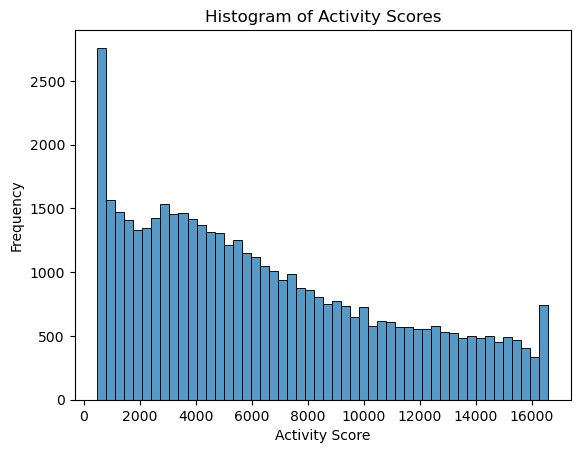

In [13]:
## Graphing Activity
sns.histplot(data=activities, x='Activity', bins=50, kde=False)
plt.xlabel('Activity Score')
plt.ylabel('Frequency')
plt.title('Histogram of Activity Scores')
plt.savefig(f'{dir}/Figs/{name}_ActivityScoreDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


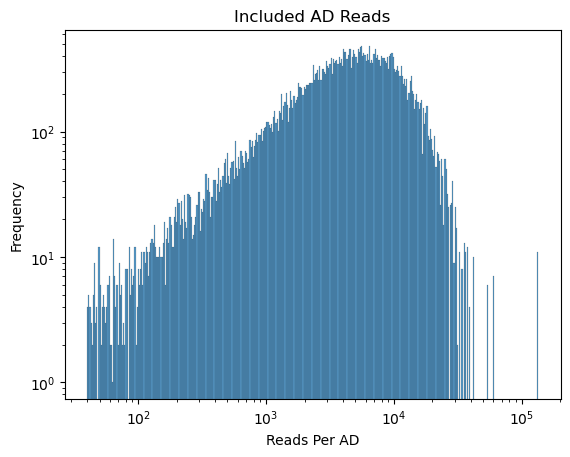

In [14]:
## Graphing AD reads

sns.histplot(data=total_reads_df, x='numreads_per_AD', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD')
plt.ylabel('Frequency')
plt.title('Included AD Reads')
plt.savefig(f'{dir}/Figs/{name}_ADReadsDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


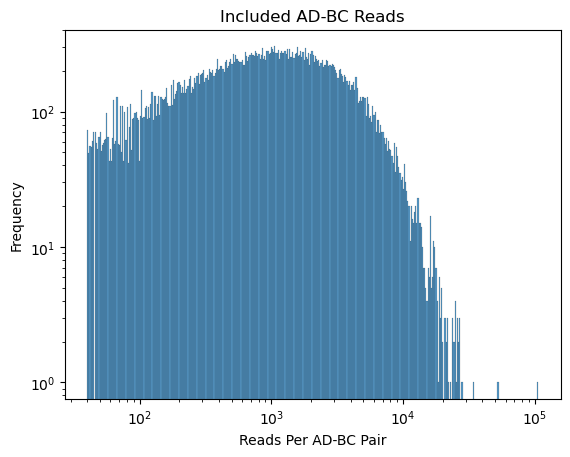

In [15]:
## Graphing AD-BC reads

sns.histplot(data=total_reads_df, x='Reads', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD-BC Pair')
plt.ylabel('Frequency')
plt.title('Included AD-BC Reads')
plt.savefig(f'{dir}/Figs/{name}_ADBCReadsDist.jpg')
plt.show()